In [20]:
# Bibliotecas utilizadas

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# Constantes utilizadas

pi = np.pi

# Funções de Bessel de segunda espécie modificadas #

As funções de Bessel de segunda espécie modificadas, $K_\alpha(t)$, também conhecidas como funções de Macdonald, constituem a segunda solução linearmente independente da equação de Bessel modificada:

$$t^2\frac{d^2y}{{dt}^2}+t\frac{dy}{dt}-(t^2+\alpha^2)y=0\,,$$

isto é, a solução geral dessa equação, para qualquer $\alpha$ complexo, é da forma:

$$y(t)=AI_\alpha(t)+BK_\alpha(t)\,.$$

Essas funções são dadas por:

$$K_\alpha(t)=\frac{\pi}{2}\frac{I_{-\alpha}(t)-I_\alpha(t)}{\sin{(\alpha\pi)}}\,.$$

Se $\alpha$ for um inteiro $n$, então $K_n(t)=0/0$. Para sair dessa indeterminação é feito o limite:

$$K_n(t)=\lim_{\alpha\to n}K_\alpha(t)\,.$$

## Visualizando as funções de Bessel de segunda espécie modificadas ##

In [21]:
def fatorial(n):
    if n == 0:
        return 1
    else:
        produto = 1
        for k in range(1, n + 1, 1):
            produto *= k
        return produto

def integrando_funcao_Gamma(x, z):
    exp = np.exp(-x)
    polinomio = np.power(x, z - 1)
    return polinomio * exp

def funcao_Gamma(Z):
    if np.isscalar(Z):
        Z = np.array([Z], dtype=float)
    resultados = []
    for z in Z:
        # Polos da função Gamma (0, -1, -2, ...)
        if z <= 0 and np.isclose(z, np.round(z), rtol=0, atol=1e-12):
            resultados.append(np.inf)
            continue

        # Desloca z para o intervalo [1, 2) onde a integral é suave e bem comportada, aproveitando a propriedade \Gamma(z+1) = z\Gamma(z)
        multiplicador = 1.0
        while z < 1:
            multiplicador /= z
            z += 1
        while z >= 2:
            z -= 1
            multiplicador *= z

        def f(x):
            return integrando_funcao_Gamma(x, z)
        resultado, erro = quad(f, 0, np.inf)
        resultados.append(resultado * multiplicador)

    resultados = np.array(resultados)
    if len(resultados) == 1:
        return resultados[0]
    return resultados

def I(t, alpha, M=50):
    if not (np.isscalar(alpha)):
        raise ValueError('\u03B1 deve ser um escalar')
    soma = 0
    for m in range(0, M + 1, 1):
        denominador2 = funcao_Gamma(m + alpha + 1)
        
        # Se Gamma divergir (polo), 1/Gamma = 0; pula o termo para evitar NaN em t = 0
        if np.isinf(denominador2):
            continue

        denominador1 = fatorial(m)
        denominador = denominador1 * denominador2

        numerador = np.power(t / 2, 2 * m + alpha)

        soma += numerador / denominador

    return soma

def K(t, alpha, M = 50):
    if not (np.isscalar(alpha)):
        raise ValueError('\u03B1 deve ser um escalar')

    # Se alpha for inteiro, aproxima o limite numericamente para evitar 0/0
    if np.isclose(alpha, np.round(alpha), rtol = 0, atol=1e-12):
        e = 1e-6
        return 0.5 * (K(t,alpha+e,M) + K(t, alpha-e,M))

    num = pi*(I(t,-alpha,M) - I(t,alpha,M))
    den = 2*np.sin(alpha*np.pi)
    return num / den

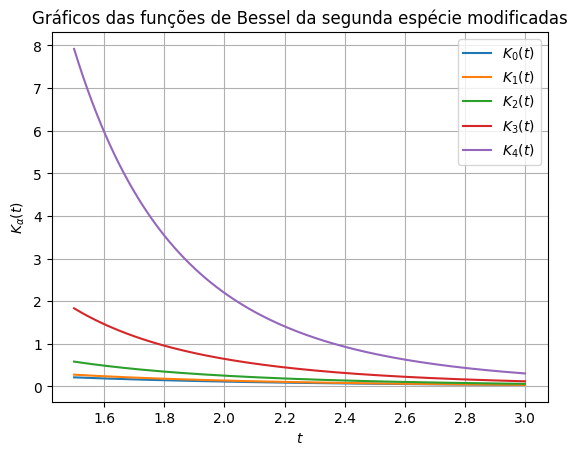

In [22]:
t0 = 1.5
tf = 3
M = 50

lista_alpha = [0,1,2,3,4]
t = np.linspace(t0, tf,201)

lista_K = []
for alpha in lista_alpha:
    K_alpha = K(t,alpha,M)
    lista_K.append(K_alpha)

for k in range(0, len(lista_alpha),1):
    if lista_alpha[k].is_integer():
        plt.plot(t, lista_K[k], label = r'$K_{%d}(t)$' %(lista_alpha[k]))
    else:
        plt.plot(t, lista_K[k], label = r'$K_{%.1f}(t)$' %(lista_alpha[k]))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$K_{\alpha}(t)$')
plt.title('Gráficos das funções de Bessel da segunda espécie modificadas')
plt.legend(loc = 'best')
plt.show()

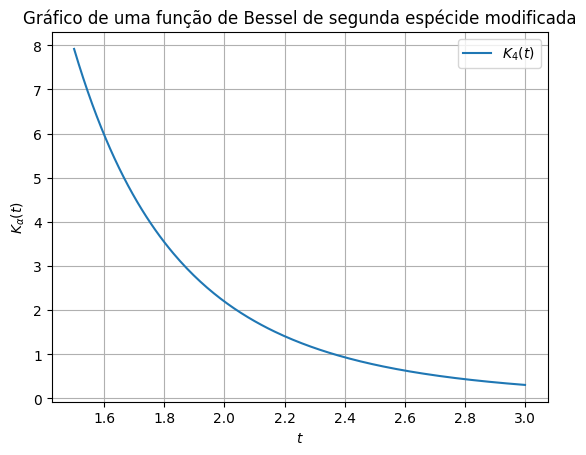

In [28]:
M = 50

alpha = 4
K_alpha = K(t, alpha, M)

if alpha.is_integer():
    plt.plot(t, K_alpha, label = r'$K_{%d}(t)$' %(alpha))
else:
    plt.plot(t, K_alpha, label = r'$K_{%.1f}(t)$' %(alpha))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$K_{\alpha}(t)$')
plt.title('Gráfico de uma função de Bessel de segunda espécide modificada')
plt.legend(loc = 'best')
plt.show()

# Propriedades das funções de Bessel de segunda espécie modificadas #

A seguir, são apresentadas algumas propriedades das funções de Bessel de segunda espécie modificadas:

##### 1 - Recorrência algébrica

$$K_{\alpha+1}(t)-K_{\alpha-1}(t)=\frac{2\alpha}{t}K_\alpha(t)\,.$$

##### 2 - Simetria par na ordem

$$K_{-\alpha}(t)=K_\alpha(t)\,.$$

##### 3 - Primeira identidade diferencial

$$\frac{d}{dt}\left[t^\alpha K_\alpha(t)\right]=-t^\alpha K_{\alpha-1}(t)\,.$$

##### 4 - Segunda identidade diferencial

$$\frac{d}{dt}\left[t^{-\alpha}K_\alpha(t)\right]=-t^{-\alpha}K_{\alpha+1}(t)\,.$$

##### 5 - Relação da derivada

$$K_{\alpha-1}(t)+K_{\alpha+1}(t)=-2\frac{dK_\alpha(t)}{dt}\,.$$

##### 6 - Caso particular $\alpha=0$ 

$$\frac{dK_0(t)}{dt}=-K_1(t)\,.$$

##### 7 - Comportamento assintótico

Para $t>0$, $K_\alpha(t)$ é estritamente positiva e decrescente, não possuindo oscilações, ao contrário de sua análoga não modificada. Quando $t\to 0^+$: $K_\alpha(t)\to+\infty$. Ainda para $t\to 0^+$:

1) Para $\alpha=0$:

$$K_0(t)\approx-\ln{\left(\frac{t}{2}\right)}-\gamma\,,$$

onde $\gamma$ é a constante de Euler-Mascheroni.

2) Para $\mathcal{Re}\{\alpha\}>0$:

$$K_\alpha(t)\approx\frac{1}{2}\Gamma(\alpha)\left(\frac{t}{2}\right)^{-\alpha}\,.$$

Para $t>>\mathcal{Re}\{\alpha\}$:

$$K_\alpha(t)\approx\sqrt{\frac{\pi}{2t}}e^{-t}\,.$$